# Laboratorium 4: CNN, splotowe sieci dla obrazów

Autor: Adam Pastuszak

Kod do sprawozdania, samo sprawozdanie jest w osobnym pliku PDF

## 1. Importy i ustawienia

In [1]:
import copy
import platform
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, TensorDataset

SEED = 0
EPOCHS = 10
LR = 1e-3
BATCH = 128
torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
sprzet = (torch.cuda.get_device_name(0) if device == "cuda"
          else f"CPU {platform.processor() or platform.machine()}, "
               f"{torch.get_num_threads()} wątki")
print("PyTorch:", torch.__version__, "| urządzenie:", device, "|", sprzet)

PyTorch: 2.15.0+cu132 | urządzenie: cpu | CPU x86_64, 2 wątki


## 2. Dane: CIFAR-10, podział trening / walidacja / test

Z 50 000 obrazów treningowych wydzielam stałe 5 000 do walidacji (ziarno 42),
średnią i odchylenie do normalizacji liczę tylko na 45 000 obrazów treningowych

In [2]:
train_raw = torchvision.datasets.CIFAR10("./data", train=True, download=True)
test_raw = torchvision.datasets.CIFAR10("./data", train=False, download=True)
classes = train_raw.classes


def to_tensor(ds):
    x = torch.tensor(ds.data).permute(0, 3, 1, 2).float().div(255)
    return x, torch.tensor(ds.targets)


x_full, y_full = to_tensor(train_raw)
x_test, y_test = to_tensor(test_raw)

perm = torch.randperm(len(x_full), generator=torch.Generator().manual_seed(42))
val_idx, train_idx = perm[:5000], perm[5000:]
mean = x_full[train_idx].mean(dim=(0, 2, 3), keepdim=True)
std = x_full[train_idx].std(dim=(0, 2, 3), keepdim=True)


def norm(x):
    return (x - mean) / std


x_train, y_train = norm(x_full[train_idx]), y_full[train_idx]
x_val, y_val = norm(x_full[val_idx]), y_full[val_idx]
x_test = norm(x_test)

train_ds = TensorDataset(x_train, y_train)
val_dl = DataLoader(TensorDataset(x_val, y_val), batch_size=1000)
test_dl = DataLoader(TensorDataset(x_test, y_test), batch_size=1000)

print("Klasy:", classes)
print("Trening:", len(x_train), "| walidacja:", len(x_val),
      "| test:", len(x_test), "| kształt obrazu:", tuple(x_train.shape[1:]))
print("mean:", mean.flatten().numpy().round(4),
      "| std:", std.flatten().numpy().round(4))

Klasy: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Trening: 45000 | walidacja: 5000 | test: 10000 | kształt obrazu: (3, 32, 32)
mean: [0.4914 0.4822 0.4466] | std: [0.247  0.2436 0.2617]


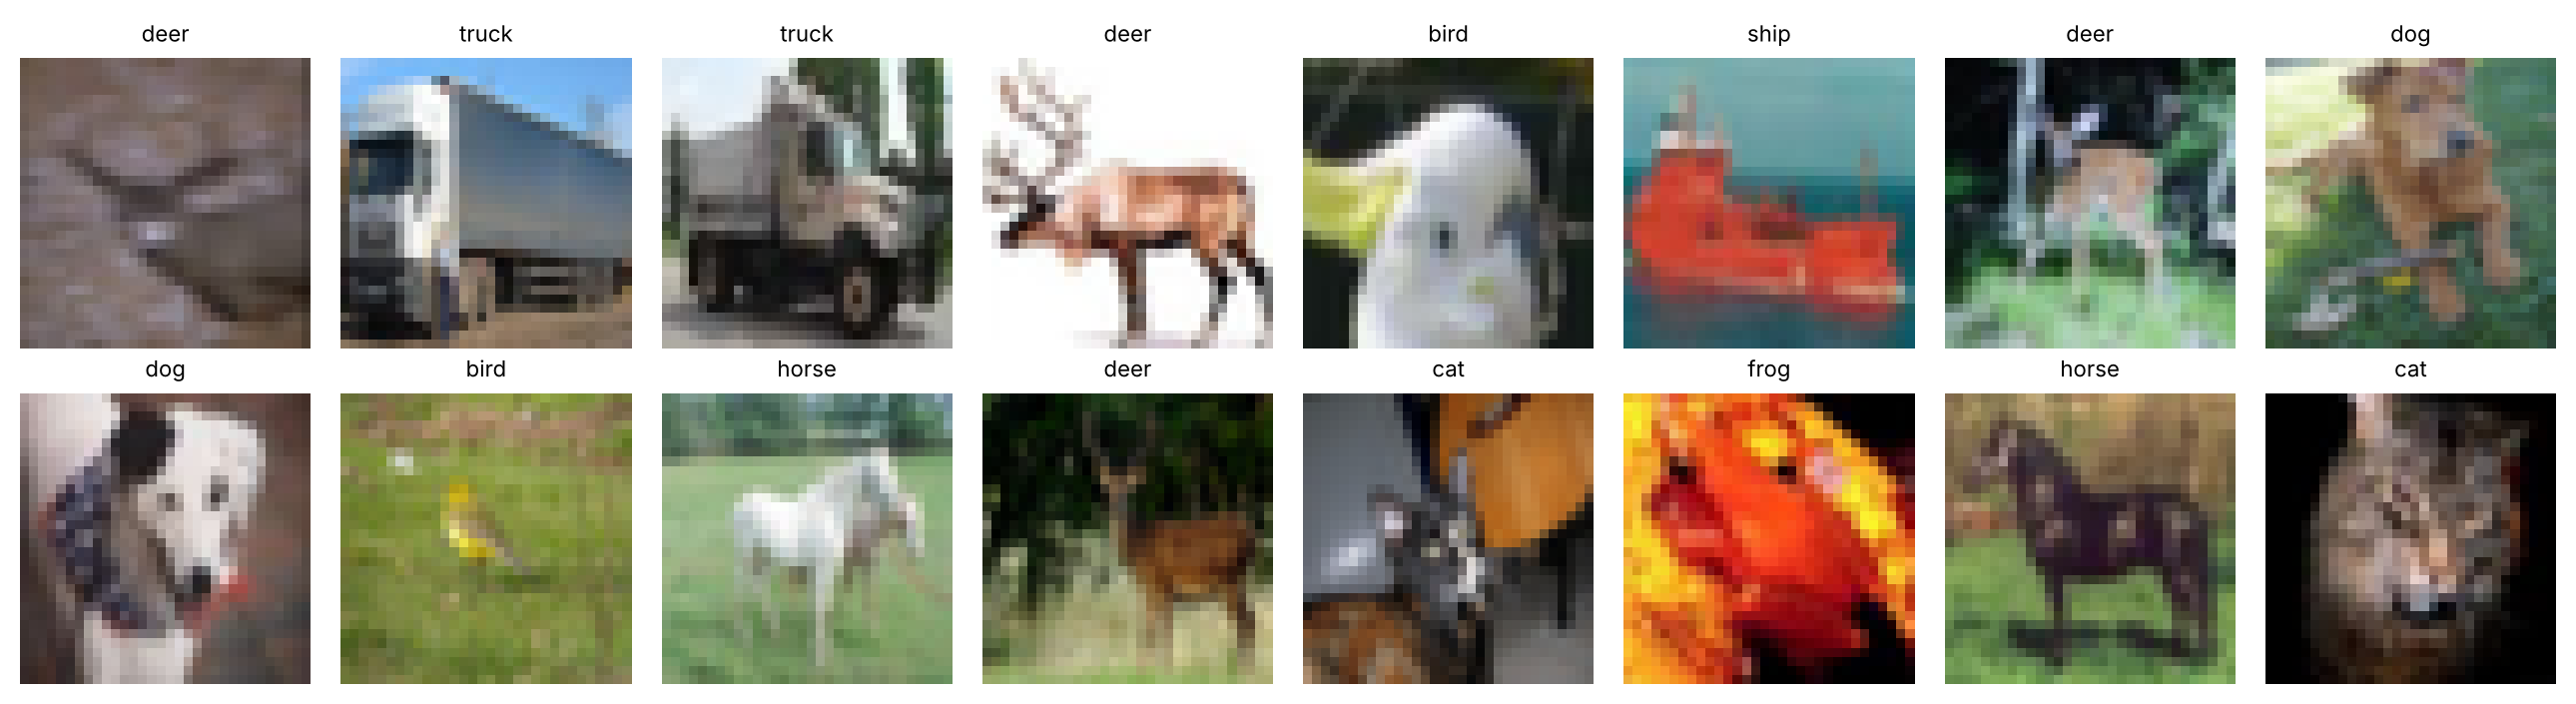

In [3]:
fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
for ax, i in zip(axes.flat, range(16)):
    img = (x_train[i] * std[0] + mean[0]).clamp(0, 1)
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(classes[y_train[i]], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Modele: MLP (baseline) i CNN

Architektury z ćwiczenia, MLP dostaje spłaszczony obraz 3·32·32 = 3072,
a CNN zaczyna od Conv2d(3, 32)

In [4]:
class MLP(nn.Module):
    def __init__(self, in_dim=3 * 32 * 32, hidden=(512, 256), n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, hidden[0]), nn.ReLU(),
            nn.Linear(hidden[0], hidden[1]), nn.ReLU(),
            nn.Linear(hidden[1], n_classes),
        )

    def forward(self, x):
        return self.net(x)


class SimpleCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()

        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(block(3, 32), block(32, 64))  # 32 -> 8
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 8 * 8, 256), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(256, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(m):
    return sum(p.numel() for p in m.parameters())


def params_by_layer(model):
    rows = []
    for name, mod in model.named_modules():
        if isinstance(mod, (nn.Linear, nn.Conv2d)):
            rows.append((name, type(mod).__name__, count_params(mod)))
    return rows


for nazwa, m in [("MLP", MLP()), ("CNN", SimpleCNN())]:
    print(f"{nazwa}: {count_params(m):,} parametrów".replace(",", " "))
    for name, typ, n in params_by_layer(m):
        print(f"   {name:16s} {typ:7s} {n:>10,}".replace(",", " "))

MLP: 1 707 274 parametrów
   net.1            Linear   1 573 376
   net.3            Linear     131 328
   net.5            Linear       2 570
CNN: 1 117 354 parametrów
   features.0.0     Conv2d         896
   features.0.3     Conv2d       9 248
   features.1.0     Conv2d      18 496
   features.1.3     Conv2d      36 928
   classifier.1     Linear   1 048 832
   classifier.4     Linear       2 570


## 4. Trening z wyborem epoki na walidacji

Ta sama funkcja dla obu modeli: Adam, lr 1e-3, batch 128, 10 epok, ziarno 0
Czas liczę tylko dla samego uczenia (bez oceny na walidacji)
Po każdej epoce zapisuję accuracy treningowe (liczone w trakcie epoki) i walidacyjne,
na końcu przywracam wagi z epoki o najwyższym accuracy walidacyjnym

In [5]:
def evaluate(model, dl):
    model.eval()
    crit = nn.CrossEntropyLoss(reduction="sum")
    loss_sum, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum / total, correct / total


def train_model(model, epochs=EPOCHS, lr=LR):
    torch.manual_seed(SEED)
    model = model.to(device)
    loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_acc": [], "val_acc": [], "val_loss": []}
    best = {"val_acc": -1.0}
    czas = 0.0
    for epoch in range(1, epochs + 1):
        model.train()
        correct, total = 0, 0
        t0 = time.time()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            out = model(xb)
            loss = crit(out, yb)
            loss.backward()
            opt.step()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
        if device == "cuda":
            torch.cuda.synchronize()
        czas += time.time() - t0
        val_loss, val_acc = evaluate(model, val_dl)
        hist["train_acc"].append(correct / total)
        hist["val_acc"].append(val_acc)
        hist["val_loss"].append(val_loss)
        print(f"  epoka {epoch:2d} | acc trening "
              f"{correct / total * 100:5.2f}% | acc walid. "
              f"{val_acc * 100:5.2f}% | strata walid. {val_loss:.3f} "
              f"| czas {czas:6.1f} s")
        if val_acc > best["val_acc"]:
            best = {"epoch": epoch, "val_acc": val_acc,
                    "state": copy.deepcopy(model.state_dict())}
    model.load_state_dict(best["state"])
    return model, hist, best, czas

## 5. Trening MLP i CNN

In [6]:
print("== MLP ==")
mlp, hist_mlp, best_mlp, t_mlp = train_model(MLP())
print("\n== CNN ==")
cnn, hist_cnn, best_cnn, t_cnn = train_model(SimpleCNN())

== MLP ==


  epoka  1 | acc trening 41.47% | acc walid. 47.04% | strata walid. 1.514 | czas    2.8 s


  epoka  2 | acc trening 48.77% | acc walid. 49.20% | strata walid. 1.456 | czas    5.5 s


  epoka  3 | acc trening 52.84% | acc walid. 50.42% | strata walid. 1.399 | czas    8.2 s


  epoka  4 | acc trening 56.30% | acc walid. 52.22% | strata walid. 1.400 | czas   11.1 s


  epoka  5 | acc trening 59.27% | acc walid. 52.72% | strata walid. 1.385 | czas   14.5 s


... (11 outputs left out)

  epoka  7 | acc trening 80.29% | acc walid. 76.86% | strata walid. 0.689 | czas  400.7 s


  epoka  8 | acc trening 81.90% | acc walid. 78.62% | strata walid. 0.607 | czas  457.2 s


  epoka  9 | acc trening 83.22% | acc walid. 78.74% | strata walid. 0.626 | czas  512.8 s


  epoka 10 | acc trening 84.46% | acc walid. 79.62% | strata walid. 0.601 | czas  568.2 s


## 6. Ocena końcowa na teście i zestawienie

Test liczony raz, dla wag z wybranej epoki

In [7]:
wyniki = {}
for nazwa, m, best, t in [("MLP", mlp, best_mlp, t_mlp),
                          ("CNN", cnn, best_cnn, t_cnn)]:
    test_loss, test_acc = evaluate(m, test_dl)
    wyniki[nazwa] = {"parametry": count_params(m), "epoka": best["epoch"],
                     "val_acc": best["val_acc"], "test_acc": test_acc,
                     "czas": t}

print(f"{'model':5s} | {'parametry':>10s} | {'epoka':>5s} | "
      f"{'acc walid.':>10s} | {'acc test':>8s} | {'czas [s]':>8s}")
print("-" * 62)
for nazwa, w in wyniki.items():
    print(f"{nazwa:5s} | {w['parametry']:>10,} | {w['epoka']:>5d} | "
          f"{w['val_acc'] * 100:>9.2f}% | {w['test_acc'] * 100:>7.2f}% | "
          f"{w['czas']:>8.1f}".replace(",", " "))
print(f"losowy baseline: 10.00% | lr {LR}, batch {BATCH}, "
      f"{EPOCHS} epok, Adam | {sprzet}")

model |  parametry | epoka | acc walid. | acc test | czas [s]
--------------------------------------------------------------
MLP   |  1 707 274 |     8 |     54.42% |   53.36% |     30.4
CNN   |  1 117 354 |    10 |     79.62% |   78.90% |    568.2
losowy baseline: 10.00% | lr 0.001, batch 128, 10 epok, Adam | CPU x86_64, 2 wątki


## 7. Krzywe accuracy obu modeli

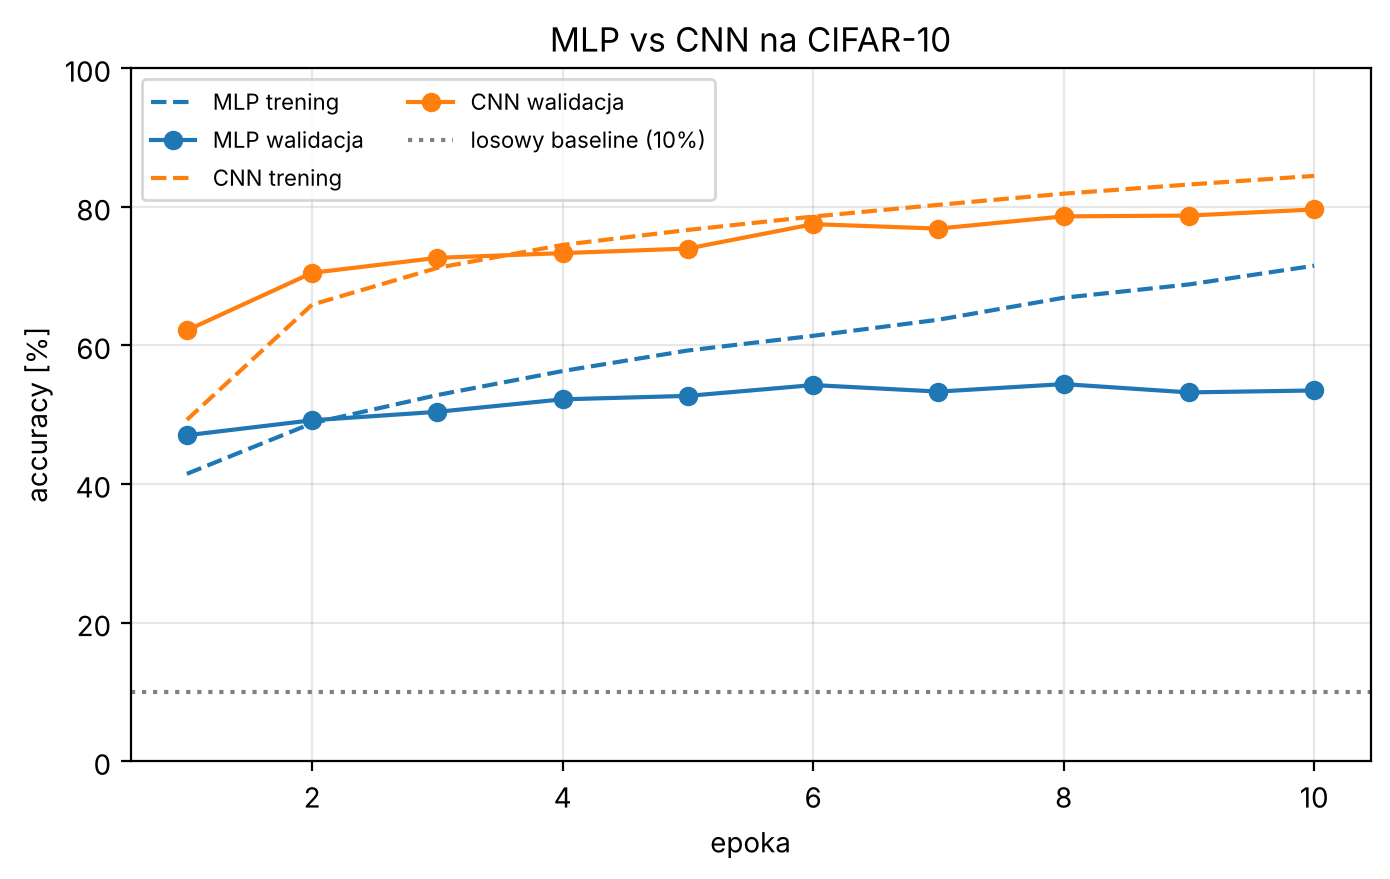

In [8]:
ep = range(1, EPOCHS + 1)
plt.figure(figsize=(8, 4.5))
for nazwa, h, kolor in [("MLP", hist_mlp, "tab:blue"),
                        ("CNN", hist_cnn, "tab:orange")]:
    plt.plot(ep, [a * 100 for a in h["train_acc"]], "--", color=kolor,
             label=f"{nazwa} trening")
    plt.plot(ep, [a * 100 for a in h["val_acc"]], "o-", color=kolor,
             label=f"{nazwa} walidacja")
plt.axhline(10, color="gray", ls=":", label="losowy baseline (10%)")
plt.xlabel("epoka")
plt.ylabel("accuracy [%]")
plt.title("MLP vs CNN na CIFAR-10")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend(fontsize=8, ncol=2)
plt.show()

## 8. Accuracy testowe dla każdej klasy i test przesunięcia

Pomocniczo do komentarza: accuracy na każdej klasie oraz accuracy na tym samym teście
przesuniętym o 2 i 4 piksele w prawo (brzeg wypełniony średnim kolorem, czyli zerem po normalizacji)

In [9]:
def predict(model, x):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(x[i:i + 1000].to(device)).argmax(1).cpu()
                          for i in range(0, len(x), 1000)])


def shift_right(x, px):
    out = torch.zeros_like(x)
    out[..., px:] = x[..., :-px]
    return out


print(f"{'klasa':12s} {'MLP':>7s} {'CNN':>7s}")
pred = {n: predict(m, x_test) for n, m in [("MLP", mlp), ("CNN", cnn)]}
for k, c in enumerate(classes):
    mask = y_test == k
    print(f"{c:12s} " + " ".join(
        f"{(pred[n][mask] == k).float().mean().item() * 100:6.1f}%"
        for n in pred))

print()
print(f"{'przesunięcie':12s} {'MLP':>7s} {'CNN':>7s}")
for px in [0, 2, 4]:
    xs = x_test if px == 0 else shift_right(x_test, px)
    print(f"{px:>4d} px      " + " ".join(
        f"{(predict(m, xs) == y_test).float().mean().item() * 100:6.2f}%"
        for m in [mlp, cnn]))

klasa            MLP     CNN


airplane       61.3%   85.7%
automobile     56.9%   86.5%
bird           39.1%   72.3%
cat            36.2%   60.1%
deer           41.1%   81.0%
dog            48.9%   67.3%
frog           59.1%   88.4%
horse          62.9%   76.8%
ship           66.3%   88.9%
truck          61.8%   82.0%

przesunięcie     MLP     CNN


   0 px       53.36%  78.90%


   2 px       48.25%  76.64%


   4 px       40.81%  71.18%
